In [1]:
import sys
import warnings
from pathlib import Path

warnings.filterwarnings("ignore")
# Permite importar el paquete `proyecto` sin instalarlo: el código vive en src/
sys.path.insert(0, str(Path.cwd().resolve().parent / "src"))

# 03 · Preprocesamiento — de las decisiones del EDA a código con pruebas

El EDA terminó con una tabla de decisiones. Aquí se aplican con **funciones de `src/proyecto/data/`**, que tienen
pruebas en `tests/`. Este notebook **solo orquesta**: llama a las funciones, verifica que cada decisión se cumpla y
guarda los datos. Hay dos motivos para no limpiar "a mano" en celdas:

1. La limpieza tiene que correr **igual** al entrenar, al validar y, más adelante, al predecir en la app.
2. Una limpieza sin pruebas es una limpieza en la que hay que confiar a ciegas.

Produce: datos limpios, la partición entrenamiento / prueba y la demostración de por qué las fechas no pueden entrar
al modelo.

In [2]:
import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from proyecto.config import (AUX_COLUMNS, FEATURES, ID_COL, LEAKAGE_SUSPECTS, PLAUSIBLE_RANGE, PROCESSED_DIR,
                             RANDOM_STATE, TARGET, TEST_SIZE)
from proyecto.data.cleaning import clean, load_raw
from proyecto.data.split import assert_disjoint, split_by_group
from proyecto.viz import CHURN, NEUTRAL, STAY, SUBTEXT, fmt_num, fmt_pct, set_style, table, titled

set_style()
pd.set_option("display.width", 160)

raw = load_raw()        # lee data/raw/bd_confiar_2.xlsx y elimina el Nit al cargar (decisión 1)
df = clean(raw)         # aplica las decisiones 3, 5, 6, 7 y 9 del EDA
print(f"antes: {raw.shape}  ->  después: {df.shape}  (mismo número de filas: {len(raw) == len(df)})")

antes: (194073, 25)  ->  después: (194073, 30)  (mismo número de filas: True)


## 1. ¿Se cumplió cada decisión?

Esto es una **verificación**, no un gráfico: si alguna decisión no se cumple, la celda falla y el notebook se detiene.

In [3]:
low, high = PLAUSIBLE_RANGE["edad"]
checks = {
    "1 · no queda el Nit (dato personal)": "Nit" not in df.columns,
    "1 · cada asociado tiene un identificador único": df[ID_COL].is_unique,
    "3 · no quedan las fechas (anio_mes_proceso, cohorte)": not {"anio_mes_proceso", "cohorte"} & set(df.columns),
    "5 · 'salió sin radicar' solo existe entre quienes no radicaron": bool((df.loc[df["exit_without_request"] == 1, TARGET] == 0).all()),
    "6 · toda edad está entre 14 y 100 años o vacía": bool(df["edad"].dropna().between(low, high).all()),
    "7 · has_loan = 1 exactamente cuando hay saldo promedio de cartera": bool((df["has_loan"] == (df["prom_saldo_cartera"] > 0)).all()),
    "9 · la marca de salario mínimo es 0 o 1": set(df["income_is_min_wage"].unique()) <= {0, 1},
    "las 24 variables del modelo existen y son numéricas": all(pd.api.types.is_numeric_dtype(df[c]) for c in FEATURES),
    "no se perdió ninguna fila": len(df) == len(raw),
}
result = pd.Series(checks, name="se cumple")
assert result.all(), result[~result]
result.to_frame()

,se cumple
1 · no queda el Nit (dato personal),True
1 · cada asociado tiene un identificador único,True
"3 · no quedan las fechas (anio_mes_proceso, cohorte)",True
5 · 'salió sin radicar' solo existe entre quienes no radicaron,True
6 · toda edad está entre 14 y 100 años o vacía,True
7 · has_loan = 1 exactamente cuando hay saldo promedio de cartera,True
9 · la marca de salario mínimo es 0 o 1,True
las 24 variables del modelo existen y son numéricas,True
no se perdió ninguna fila,True


## 2. Lo que queda vacío (y por qué está bien)

La limpieza **no inventa datos**: marca como vacío lo imposible y deja la imputación para el `Pipeline` de la etapa 4,
que aprende la mediana **solo con el conjunto de entrenamiento**. Imputar aquí, con todos los datos, sería otra forma
de fuga.

In [4]:
missing = df[FEATURES].isna().sum().loc[lambda s: s > 0]
print("Vacíos en las variables del modelo:", {k: int(v) for k, v in missing.items()})
print(f"Equivalen al {fmt_pct(missing.sum() / len(df), 3)} de las filas.")
print("\nColumnas que acompañan a los datos pero NO son variables del modelo:", AUX_COLUMNS + [ID_COL])
print("Sospechas de fuga que se medirán con y sin ellas en la etapa 4:", LEAKAGE_SUSPECTS + ["ingresos"])

Vacíos en las variables del modelo: {'edad': 39}
Equivalen al 0,020 % de las filas.

Columnas que acompañan a los datos pero NO son variables del modelo: ['process_year', 'exit_without_request', 'income_is_min_wage', 'stratum', 'associate_id']
Sospechas de fuga que se medirán con y sin ellas en la etapa 4: ['porc_meses_publiturno', 'prom_asesorias_publiturno', 'rel_min-max_saldo_cartera', 'ingresos']


## 3. La partición

**Unidad de análisis: el asociado.** Cada uno aparece una sola vez, así que partir por asociado equivale a partir por
fila. Igual se usa la partición **por grupo** (`split_by_group`): si el equipo reconstruye el dataset como panel
mensual, seguirá siendo correcta sin tocar el código, y la prueba `tests/test_split.py` lo garantiza.

La partición se **estratifica por grupo** (radicó / sigue activo / salió sin radicar), para que entrenamiento y prueba
tengan la misma mezcla. Prueba: 20 %, semilla 42. **Se parte una sola vez.**

In [5]:
train, test = split_by_group(df, group_col=ID_COL, strat_col="stratum", test_size=TEST_SIZE, seed=RANDOM_STATE)
assert_disjoint(train, test, group_col=ID_COL)
assert len(train) + len(test) == len(df)

summary = pd.DataFrame({
    "asociados": [len(train), len(test)],
    "% del total": [len(train) / len(df), len(test) / len(df)],
    "radicó": [train[TARGET].mean(), test[TARGET].mean()],
    "salió sin radicar": [train["exit_without_request"].mean(), test["exit_without_request"].mean()],
    "asociados en ambos lados": [len(set(train[ID_COL]) & set(test[ID_COL]))] * 2,
}, index=["entrenamiento", "prueba (cerrada)"])
display(table(summary, pct_cols=["% del total", "radicó", "salió sin radicar"]))

,asociados,% del total,radicó,salió sin radicar,asociados en ambos lados
entrenamiento,155.258,"80,0 %","20,9 %","12,2 %",0
prueba (cerrada),38.815,"20,0 %","20,9 %","12,2 %",0


**Lectura.** Ningún asociado está en los dos lados, no se pierde ninguna fila y las proporciones de quienes radicaron
y de quienes salieron sin radicar son prácticamente idénticas en las dos partes: la estratificación funcionó.
**Desde aquí, la prueba queda cerrada** hasta la etapa 7. Todo lo que se decida (variables, modelo, umbral) se decide
con el entrenamiento y validación cruzada.

## 4. El momento central: ¿por qué las fechas no pueden entrar?

En CreditSight la fuga venía de partir por fila con clientes repetidos. **Aquí no hay clientes repetidos: la fuga está
en las fechas.** El EDA mostró que el mes del registro casi dice la respuesta y que `cohorte + antig_meses` lo
reconstruye. Lo comprobamos con números: el **mismo modelo**, los **mismos datos de entrenamiento**, validación cruzada
de 5 pliegues, y solo cambia si se le da o no la fecha de vinculación.

*(Se usa solo el conjunto de entrenamiento. La prueba sigue cerrada.)*

In [6]:
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.model_selection import StratifiedKFold, cross_validate

# La fecha de vinculación (meses desde enero de 2017) se recupera del crudo solo para este experimento
cohort = pd.PeriodIndex(raw["cohorte"], freq="M")
cohort_month = pd.Series((cohort.year - 2017) * 12 + cohort.month - 1, index=raw[ID_COL], name="cohort_month")
train_exp = train.assign(cohort_month=train[ID_COL].map(cohort_month))

model = HistGradientBoostingClassifier(random_state=RANDOM_STATE)
folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)
variants = {
    "sin fechas (como quedó la limpieza)": FEATURES,
    "con la fecha de vinculación (cohorte)": FEATURES + ["cohort_month"],
}
rows, per_fold = [], {}
for name, cols in variants.items():
    cv = cross_validate(model, train_exp[cols], train_exp[TARGET], cv=folds,
                        scoring={"AUC": "roc_auc", "PR-AUC": "average_precision"})
    per_fold[name] = cv
    rows.append({"variante": name, "AUC": cv["test_AUC"].mean(), "AUC (desv. entre pliegues)": cv["test_AUC"].std(),
                 "PR-AUC": cv["test_PR-AUC"].mean(), "PR-AUC (desv.)": cv["test_PR-AUC"].std()})
leak_table = pd.DataFrame(rows).set_index("variante")
display(table(leak_table, decimals=4))

,AUC,AUC (desv. entre pliegues),PR-AUC,PR-AUC (desv.)
variante,,,,
sin fechas (como quedó la limpieza),"0,9002","0,0017","0,7161","0,0036"
con la fecha de vinculación (cohorte),"0,9772","0,0010","0,9062","0,0034"


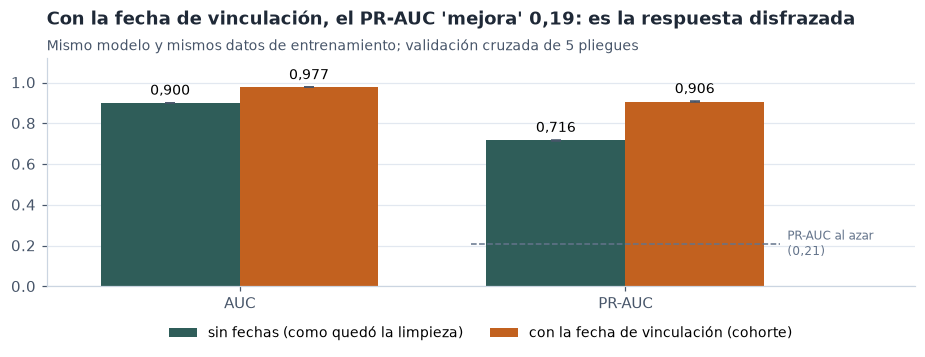

In [7]:
fig, ax = plt.subplots(figsize=(8.5, 3.4))
metrics = ["AUC", "PR-AUC"]
x = np.arange(len(metrics))
width = 0.36
for i, (name, color) in enumerate(zip(variants, [STAY, CHURN])):
    means = [leak_table.loc[name, m] for m in metrics]
    stds = [leak_table.loc[name, "AUC (desv. entre pliegues)"], leak_table.loc[name, "PR-AUC (desv.)"]]
    bars = ax.bar(x + (i - 0.5) * width, means, width, yerr=stds, color=color, label=name,
                  error_kw={"ecolor": SUBTEXT, "capsize": 3})
    ax.bar_label(bars, labels=[fmt_num(v, 3) for v in means], padding=3, fontsize=9)
base_rate = train[TARGET].mean()
ax.plot([0.6, 1.4], [base_rate, base_rate], color=NEUTRAL, ls="--", lw=1, zorder=3)
ax.text(1.42, base_rate, f"PR-AUC al azar\n({fmt_num(base_rate, 2)})", color=NEUTRAL, fontsize=8, va="center")
ax.set_xlim(-0.5, 1.75)
ax.set_xticks(x); ax.set_xticklabels(metrics); ax.set_ylim(0, 1.12); ax.grid(axis="x", visible=False)
ax.legend(loc="upper center", ncol=2, bbox_to_anchor=(0.5, -0.12))
gain = leak_table["PR-AUC"].iloc[1] - leak_table["PR-AUC"].iloc[0]
titled(ax, f"Con la fecha de vinculación, el PR-AUC 'mejora' {fmt_num(gain, 2)}: es la respuesta disfrazada",
       "Mismo modelo y mismos datos de entrenamiento; validación cruzada de 5 pliegues")
plt.tight_layout(); plt.show()

**Lectura.** Con la fecha de vinculación el modelo **parece** mucho mejor (tabla y gráfico). Esa ventaja es **falsa**:
junto con la antigüedad, la fecha de vinculación reconstruye el mes del registro, y el mes del registro dice si el
asociado sigue activo en diciembre de 2025 o no. El modelo no aprende a anticipar el retiro: **lee cuándo se tomó la
foto**. En producción todos los asociados se evalúan el mismo mes, así que esa "señal" no existe: el desempeño real es,
**como máximo**, el de la barra verde. Y puede ser menor, porque la barra verde todavía incluye las sospechas de fuga
del EDA.

Es una fuga **sin un solo error de código**: el pipeline corre, las métricas se ven bien y todo está mal. Por eso la
limpieza elimina las dos fechas (`drop_time_columns`) y una prueba lo verifica (`tests/test_cleaning.py`).

> El mismo razonamiento aplica, en menor grado, a las sospechas de la sección 6 del EDA (visitas, cartera mínima en
> cero, ingreso en pesos nominales). Esas se miden en la etapa 4 con la métrica de negocio.

## 5. Guardar los datos de la etapa

Se guardan en `data/processed/` (no se versionan: se regeneran corriendo este notebook). La prueba **no se vuelve a
abrir** hasta la validación final.

In [8]:
PROCESSED_DIR.mkdir(parents=True, exist_ok=True)
joblib.dump(train, PROCESSED_DIR / "train.joblib")
joblib.dump(test, PROCESSED_DIR / "test.joblib")
print(f"entrenamiento: {fmt_num(len(train))} asociados -> data/processed/train.joblib")
print(f"prueba:        {fmt_num(len(test))} asociados -> data/processed/test.joblib  (cerrada hasta la etapa 7)")
print("columnas guardadas:", len(train.columns), "=", len(FEATURES), "variables +", TARGET, "+", ID_COL, "+", len(AUX_COLUMNS), "auxiliares")

entrenamiento: 155.258 asociados -> data/processed/train.joblib
prueba:        38.815 asociados -> data/processed/test.joblib  (cerrada hasta la etapa 7)
columnas guardadas: 30 = 24 variables + sol_retiro + associate_id + 4 auxiliares


## 6. Las pruebas automáticas

Desde la raíz del repositorio:

```bash
pytest -q
```

| Archivo | Qué garantiza |
|---|---|
| `tests/test_cleaning.py` | Una prueba por decisión: sin Nit, sin fechas, edad imposible → vacío, marcas de salario mínimo y de producto, "salió sin radicar" bien asignado, sin filas perdidas |
| `tests/test_split.py` | **Ningún asociado en dos particiones**, ninguna fila perdida, mezcla de grupos conservada. La prueba **falla** si se cambia a partición por fila con asociados repetidos (comprobado) |
| `tests/test_business.py` | Las métricas de negocio del notebook 01, con cuentas hechas a mano |

## Entregable de esta etapa (hito H1)

- [x] La limpieza corre de principio a fin desde el repositorio, sin pasos manuales.
- [x] La partición respeta la unidad de análisis (el asociado) y está **verificada con una prueba**.
- [x] `pytest` en verde.
- [x] `data/raw/` no cambió (solo se lee).
- [x] Unidad de análisis declarada por escrito (sección 3 y `reports/01_eda.md`).

**Siguiente (clase 3):** `04_features.ipynb`: pipeline base, sospechas de fuga con y sin, y torneo de modelos.